# EE-411 — Fundamentals of Inference and Learning

## Exercise Session 9 — Training convolutional neural networks

**Learning objectives**

- Train convolutional neural networks (CNNs) on MNIST and CIFAR-10.
- Use a validation set to compare training configurations.
- Explore batch normalization, learning-rate schedules and residual connections.

**Prerequisites:** TP8 (PyTorch, automatic differentiation and neural network training).

**Session format:** We will run and discuss the provided experiments together. Only the labelled evaluated exercise is assessed; discussion prompts require no written answers.


## Part 1 — CNNs and model selection


### Convolutional Neural Networks

Great sources:
- https://poloclub.github.io/cnn-explainer/
- https://setosa.io/ev/image-kernels/

![](https://poloclub.github.io/cnn-explainer/assets/figures/convlayer_detailedview_demo.gif)

**Why convolutions and not fully-connected layers?** In the previous lab, we used a MultiLayer Perceptron (MLP) to perform classification on the MNIST dataset of handwritten digits. However, MLPs expect a vector as an input and, hence, our first step was to *flatten* the image; from an input of shape $(1, 28, 28)$ we got a vector of $1\times28\times28=784$ elements. Then, each layer of the MLP is fully connected, meaning that all $784$ elements are fed into each neuron of the next layer.

Does this sound reasonable?

No! First, by flattening we implicitly lose *local* information. Assume you look at pixel in location $(5,5)$, then the neighboring pixels $(4,5),(6,5), (5,4), (5,6),\dots$ are important and must be "somewhat similar". Second, by using all elements of the previous layer. the top left and bottom right pixels are used in the same computation.

Convolutional Neural Networks address these (and more) concerns and are suitable for the vision domain. But, what are convolutions? We start with a small matrix of weights, e.g. $3\times3$, which is called a kernel. The kernel is then slid over the 2D input and we perform elementwise multiplication with the values the kernel is currently on. The summation of the $3\times3=9$ elements is the output for the pixel. Hence, the kernel performs a "local" computation. *Back in the day*, kernels were hand-designed to perform a specific operation. For example, the Sobel operator is used for edge-detection:

$$
\mathbf{G}_x=\left[\begin{array}{ccc}
+1 & 0 & -1 \\
+2 & 0 & -2 \\
+1 & 0 & -1
\end{array}\right] * \mathbf{A} \quad \text { and } \quad \mathbf{G}_y=\left[\begin{array}{ccc}
+1 & +2 & +1 \\
0 & 0 & 0 \\
-1 & -2 & -1
\end{array}\right] * \mathbf{A}
$$

$$
\mathbf{G}=\sqrt{\mathbf{G}_x^2+\mathbf{G}_y^2}
$$

For example:

![](https://miro.medium.com/max/640/1*m9XHMKQPY6mKYsaykuVAsw.webp)

Creating filters for every different scenario requires domain knowledge and is cumbersome. (Convolutional) Neural Networks learn the values of these filters in an "end-to-end" manner!

In [ ]:
!git clone https://github.com/IdePHICS/FundamentalLearningEPFL.git

In [2]:
import sys
sys.path.append('/content/FundamentalLearningEPFL/TP9/')
import training_utils

In [3]:
import importlib, types
imp = types.ModuleType("imp")
imp.reload = importlib.reload
sys.modules["imp"] = imp

%load_ext autoreload
%autoreload 2

In [4]:
# import our "local" library of functions
from training_utils import train_epoch, fit, predict, visualize_images, plot_loss

# also import everything else that we need
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

In [5]:
# define the hyperparameters
SEED = 42
BATCH_SIZE = 128
TEST_BATCH_SIZE = 1024
NUM_WORKERS = 0
LEARNING_RATE = 0.1
CNN_EPOCHS = 10

# find out which device is available
DEVICE = None
if torch.cuda.is_available():
    # Requires NVIDIA GPU with CUDA installed
    DEVICE = torch.device("cuda")
elif torch.mps.is_available():
    # Requires Apple computer with M1 or later chip
    DEVICE = torch.device("mps")
else:
    # Not recommended, because it's slow. Move to Google Colab!
    DEVICE = torch.device("cpu")

DEVICE = torch.device("cpu")
print(DEVICE)

cpu


In [6]:
transform = torchvision.transforms.ToTensor()

# load the train dataset
train_dataset = torchvision.datasets.MNIST(
    root='./data/',
    train=True,
    download=True,
    transform=transform)

# load the test dataset
test_dataset = torchvision.datasets.MNIST(
    root='./data/',
    train=False,
    download=True,
    transform=transform)

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=NUM_WORKERS)


test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS)

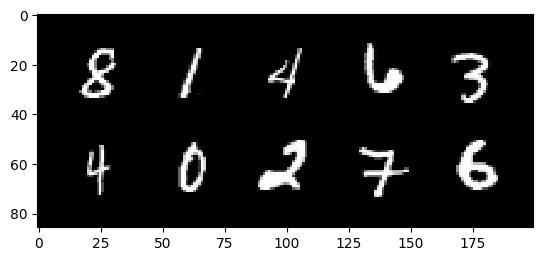

In [7]:
visualize_images(train_dataloader)

In [8]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # We use a Sequential, i.e. the inputs pass through each of
        # the modules below, one by one.
        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                stride=1,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=1,
                padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # fully connected layer, output 10 classes
        self.out = nn.Linear(1568, 10)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1) #reshape the tensor
        x = self.out(x)
        return x


In [9]:
# initialize model
torch.manual_seed(SEED)
cnn = CNN().to(DEVICE)

# define the optimizer
optimizer = torch.optim.SGD(cnn.parameters(), lr=0.1)

# train the CNN
losses = fit(
    model=cnn,
    train_dataloader=train_dataloader,
    optimizer=optimizer,
    epochs=10,
    device=DEVICE
)

predict(model=cnn, test_dataloader=test_dataloader, device=DEVICE)

Epoch 0: Loss=0.3815408610442935
Epoch 1: Loss=0.1083036904920266
Epoch 2: Loss=0.08221782171236935
Epoch 3: Loss=0.06922942181544772
Epoch 4: Loss=0.06033286918351836
Epoch 5: Loss=0.05455297204667826
Epoch 6: Loss=0.050825051661493426
Epoch 7: Loss=0.04596743301035705
Epoch 8: Loss=0.04409060102285765
Epoch 9: Loss=0.04101646101838951
Test set: Avg. loss: 0.0575, Accuracy: 9802/10000 (98%)


(0.05747973146438599, tensor(98.0200))

### CIFAR-10

We reserve 10,000 training images for validation in the later comparisons.

In [10]:
transform = torchvision.transforms.ToTensor()

cifar_dataset = torchvision.datasets.CIFAR10(
    root='./data/', train=True, download=True, transform=transform)
cifar_test_dataset = torchvision.datasets.CIFAR10(
    root='./data/', train=False, download=True, transform=transform)

cifar_train_dataset, cifar_valid_dataset = random_split(
    cifar_dataset, [40000, 10000],
    generator=torch.Generator().manual_seed(SEED))

train_dataloader = DataLoader(
    cifar_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=NUM_WORKERS)
valid_dataloader = DataLoader(
    cifar_valid_dataset, batch_size=TEST_BATCH_SIZE, num_workers=NUM_WORKERS)
test_dataloader = DataLoader(
    cifar_test_dataset, batch_size=TEST_BATCH_SIZE, num_workers=NUM_WORKERS)

100%|██████████| 170M/170M [16:00<00:00, 177kB/s]    


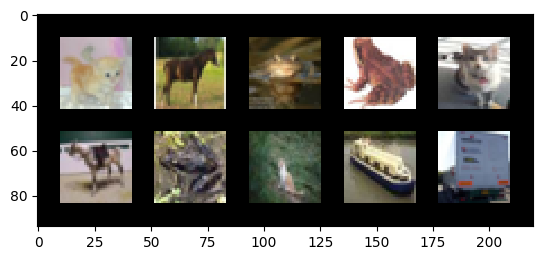

In [11]:
visualize_images(train_dataloader)

In [12]:
class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # We use a Sequential, i.e. the inputs passes through each of
        # the modules below, one-by-one
        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels=3, #COLORED IMAGES!
                out_channels=16,
                kernel_size=3,
                stride=1,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=1,
                padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # fully connected layer, output 10 classes
        self.out = nn.Linear(2048, 10) #Now is 32x32 images!

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.out(x)
        return x

torch.manual_seed(SEED)
train_dataloader.generator.manual_seed(SEED)
cnn_cifar = CifarCNN().to(DEVICE)
optimizer = torch.optim.SGD(cnn_cifar.parameters(), lr=LEARNING_RATE)

cifar_baseline_losses = fit(
    model=cnn_cifar,
    train_dataloader=train_dataloader,
    optimizer=optimizer,
    epochs=CNN_EPOCHS,
    device=DEVICE)
_, cifar_baseline_accuracy = predict(
    cnn_cifar, valid_dataloader, DEVICE, verbose=False)
cifar_baseline_accuracy = cifar_baseline_accuracy.item()
print(f"Validation accuracy: {cifar_baseline_accuracy:.1f}%")

Epoch 0: Loss=2.0000579181951457
Epoch 1: Loss=1.6029779096000112
Epoch 2: Loss=1.4253937204044087
Epoch 3: Loss=1.3077639855515844
Epoch 4: Loss=1.2168565994253555
Epoch 5: Loss=1.1427338612727083
Epoch 6: Loss=1.0920552287619716
Epoch 7: Loss=1.0457772488792103
Epoch 8: Loss=1.0084460651912628
Epoch 9: Loss=0.979611592932631
Validation accuracy: 60.5%


**Takeaway:** CIFAR-10 is harder than MNIST. We will compare training choices using a validation set.

### Validation set

We return to MNIST for short comparisons of learning rate and momentum.

Before looking into tips and tricks for boosting the performance of a model, we need to establish a proper evaluation protocol. This is where the validation set comes in.

In the real world, we do not have access to the test set, e.g., customer churning or self-driving cars. But, still, we need to evaluate the performance of our models on *unseen data*. The most common way is to split the training set into training+validation.

In [13]:
# load the train dataset
train_dataset = torchvision.datasets.MNIST(
    root='./data/',
    train=True,
    download=True,
    transform=transform)

# load the test dataset
test_dataset = torchvision.datasets.MNIST(
    root='./data/',
    train=False,
    download=True,
    transform=transform)

print(train_dataset)

# Split the dataset into 50k-10k samples for training-validation.
train_dataset,  valid_dataset = random_split(
    train_dataset,
    lengths=[50000, 10000],
    generator=torch.Generator().manual_seed(SEED) #use a generator to insure reproducibilty
)

# what is the type of the "new" training dataset?
print(train_dataset)

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data/
    Split: Train
    StandardTransform
Transform: ToTensor()


In [14]:
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=NUM_WORKERS)

valid_dataloader = DataLoader(
    dataset=valid_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS)

test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS)

**Guided experiment:** The training function below adds validation monitoring.

In [15]:
from typing import Optional

def fit(
    model: nn.Module,
    train_dataloader: DataLoader,
    optimizer: torch.optim.Optimizer,
    epochs: int,
    device: torch.device,
    valid_dataloader: Optional[DataLoader]=None):
    '''
    the fit method simply calls the train_epoch() method for a
    specified number of epochs.
    '''

    # Keep track of the losses in order to visualize them later
    # Train for numerous epochs:
    train_losses = []
    valid_losses = []
    valid_accs = []
    for epoch in range(epochs):
        train_loss = train_epoch(
            model=model,
            train_dataloader=train_dataloader,
            optimizer=optimizer,
            device=device
        )
        train_losses.append(train_loss)

        if valid_dataloader is not None:
            valid_loss, valid_acc = predict(model, valid_dataloader, device, verbose=False)
            valid_losses.append(valid_loss)
            valid_accs.append(valid_acc.item())

        if valid_dataloader is None:
            print(f"Epoch {epoch}: Train Loss={train_loss:.4f}")
        else:
            print(f"Epoch {epoch}: Train Loss={train_loss:.4f}, Validation Loss={valid_loss:.4f}, Validation acc={valid_acc:.4f}")

    return train_losses, valid_losses, valid_accs

### Importance of optimizer and learning rate

So far in this lab, we have used the same learning rate and optimizer (vanilla SGD). However, the choice of optimizer and the corresponding hyperparameters play a crucial role in the final performances.

#### Learning rate

A small learning rate can slow training; a large one can make training unstable.

#### Optimizer

In this lab we have used (mini-batch) Stochastic Gradient Descent (SGD). For simplicity we consider the case with only one sample per step. The update rule is the following:

$$
\mathbf{w}^{(\tau+1)} \gets \mathbf{w}^{(\tau)} - \eta\nabla L\left(\mathbf{x}, y;\mathbf{w}^{(\tau)}\right)
$$

How can we improve our algorithm and encourage faster convergence? Momentum can actually help. The idea is simple: we will use the update made on the previous step and incorporate it to our current update, giving momentum to our algorithm. The actual update rule is the following:

$$
\begin{align}
\mathbf{v}^{(\tau+1)} &\gets \gamma\mathbf{v}^{(\tau)} + \nabla L\left(\mathbf{x}, y;\mathbf{w}^{(\tau)}\right)
\\
\mathbf{w}^{(\tau+1)} &\gets \mathbf{w}^{(\tau)} - \eta \mathbf{v}^{(\tau+1)}
\end{align}
$$

Apart from making convergence faster, momentum has other benefits:
* dampens oscillations
* helps us navigate ravines around local optima [1]

If you are interested in exploring further the various optimizers take a look at reference [1].

----
[1] Ruder, S., 2016. An overview of gradient descent optimization algorithms. arXiv preprint arXiv:1609.04747.

**Guided experiment:** Compare three learning rates and one run with momentum on MNIST. Each run starts afresh and uses five epochs.

**Discussion:** How do the settings affect the speed and stability of learning?

lr=0.001, momentum=0
Epoch 0: Train Loss=2.2897, Validation Loss=2.2709, Validation acc=28.1400
Epoch 1: Train Loss=2.2483, Validation Loss=2.2203, Validation acc=48.9300
Epoch 2: Train Loss=2.1778, Validation Loss=2.1220, Validation acc=60.7200
Epoch 3: Train Loss=2.0276, Validation Loss=1.9019, Validation acc=66.1300
Epoch 4: Train Loss=1.7030, Validation Loss=1.4696, Validation acc=71.8600
lr=0.1, momentum=0
Epoch 0: Train Loss=0.4266, Validation Loss=0.1582, Validation acc=95.3700
Epoch 1: Train Loss=0.1191, Validation Loss=0.1307, Validation acc=95.7800
Epoch 2: Train Loss=0.0893, Validation Loss=0.0859, Validation acc=97.5900
Epoch 3: Train Loss=0.0727, Validation Loss=0.0757, Validation acc=97.8300
Epoch 4: Train Loss=0.0646, Validation Loss=0.0698, Validation acc=97.9000
lr=0.5, momentum=0
Epoch 0: Train Loss=0.4197, Validation Loss=0.1693, Validation acc=94.8700
Epoch 1: Train Loss=0.1012, Validation Loss=0.1034, Validation acc=96.9100
Epoch 2: Train Loss=0.0739, Validation Lo

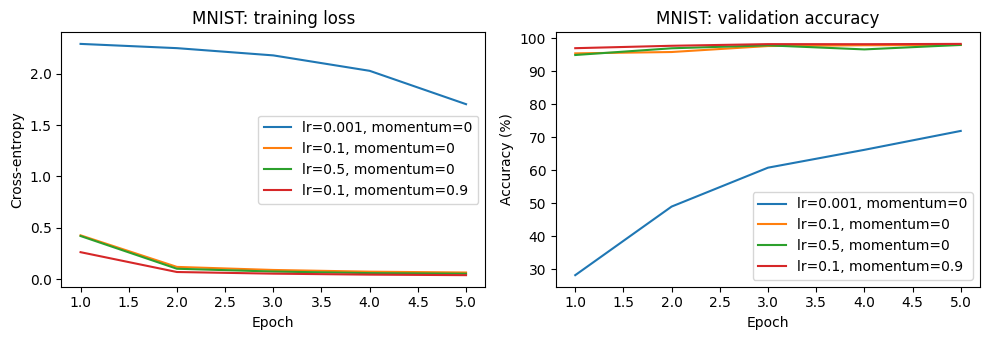

In [16]:
mnist_histories = {}
settings = [(0.001, 0), (0.1, 0), (0.5, 0), (0.1, 0.9)]

for learning_rate, momentum in settings:
    torch.manual_seed(SEED)
    train_dataloader.generator.manual_seed(SEED)
    cnn = CNN().to(DEVICE)
    optimizer = torch.optim.SGD(
        cnn.parameters(), lr=learning_rate, momentum=momentum)
    label = f"lr={learning_rate}, momentum={momentum:g}"
    print(label)
    train_losses, _, valid_accs = fit(
        cnn, train_dataloader, optimizer, epochs=5, device=DEVICE,
        valid_dataloader=valid_dataloader)
    mnist_histories[label] = (train_losses, valid_accs)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, (losses, accuracies) in mnist_histories.items():
    epochs = range(1, len(losses) + 1)
    axes[0].plot(epochs, losses, label=label)
    axes[1].plot(epochs, accuracies, label=label)
axes[0].set(title="MNIST: training loss", ylabel="Cross-entropy")
axes[1].set(title="MNIST: validation accuracy", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

### Hyperparameters: Learning rate and batch size

While intuition can help us select the settings of an experiment, the choice becomes complicated when more hyperparameters must be taken account. Just to name a few, we might want to select learning rate, momentum or optimizer, batch size, number of layers, width of layers, etc.

Hence, we need a systematic way to approach this problem. The simplest way is to perform a grid search: define a list of choices for each hyperparameter and search over all combinations.

## Part 2 — Improving training

In the previous part we implemented CNNs using the `PyTorch` library. Our experiments showed that for image classification a CNN architecture yields good results on MNIST and, depending on the complexity of the network, "good" results on CIFAR10. However, by dealing with MNIST, you might have gotten the wrong impression: "everythings works magically out-of-the-box in Deep Learning". Reality is not so rosy and we must go to great lengths to replicate our success on MNIST on other datasets.

In this part, we will explore common pitfalls as well as tips and tricks to resolve them. These simple methods will provide superior performance and are very easy to incorporate in our pipeline.

Specifically, we will talk about:
- Batch Normalization
- Learning rate scheduler
- Residual Connections

So... let's get started!


In [17]:
# first we load all the necessary libraries

import torch.nn.functional as F

In [18]:
# Return to the same CIFAR-10 split used for the baseline.
train_dataset = cifar_train_dataset
valid_dataset = cifar_valid_dataset
test_dataset = cifar_test_dataset

In [19]:
train_dataloader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=NUM_WORKERS)
valid_dataloader = DataLoader(
    valid_dataset, batch_size=TEST_BATCH_SIZE, num_workers=NUM_WORKERS)
test_dataloader = DataLoader(
    test_dataset, batch_size=TEST_BATCH_SIZE, num_workers=NUM_WORKERS)

### Batch normalization

We want to learn fast and converge at the same time. If we use a small learning rate, we will converge but it will be too slow. On the other hand, if we use a large learning rate, our training will become inconsistent and we will bounce all over the place and never converge. Additionaly, higher learning rates  cause exploding or vanishing gradients i.e. the phenomenon where the multiplication of gradients via the chain rule induces a compound effect on the earlier layers, preventing them from learning.

Can we have the best of both worlds? Enter **Batch Normalization**.

1. What does BatchNorm aims to solve? We want to
    * avoid unstable gradients,
    * allow faster learning rates leading to faster convergence,
    * reduce the effect of initialization.

2. What does BatchNorm actually do?

Suppose we are given values of $x$ over a mini-batch $B=\{x_i\}_{i=1}^m$. Our goal is to learn some parameters $\gamma$ and $\beta$ that perform the proper scaling.

- First, we compute the mini-batch mean
    $$
    \mu_{B}=\frac{1}{m}\sum_{i=1}^mx_i
    $$
and mini-batch variance
    $$
    \sigma^2_{B}=\frac{1}{m}\sum_{i=1}^m (x_i-\mu_{B})^2
    $$
- we use these quantities to normalize our input
    $$
    x_i\leftarrow\frac{x_i-\mu_{B}}{\sqrt{\sigma^2_{B}+\epsilon}}
    $$
- We scale, shift and return the output
    $$
    y_i=\gamma x_i+\beta\equiv \text{BN}_{\gamma, \beta}(x_i)
    $$
Essentially, for each mini-batch we normalize the inputs by subtracting their mean and dividing by their standard deviation (estimated based on the statistics of the current mini-batch)  


3. Why does BatchNorm work?

    * BatchNorm is widely used (e.g. the original paper [1] has over 70000 citations). However, the reasons of its success are not perfectly clear.
    * The original authors claim that BatchNorm helps alleviate *internal covariate shift*, i.e. the phenomenon of shifting input distributions. Specifically, the input to each layer can be seen as a data distribution that the layer is trying to “learn”. The model, though, does not see the whole dataset but simply mini-batches. If this distribution stays consistent across batches, the layer can "learn effectively".  But, does this happen in practice?
    * the reality is that different mini-batches have different statistics, e.g. mean, variance, etc., making the input distribution to the layers jump around. In other words, the input distribuion shifts for every mini-batch. We are trying to learn a "moving target". What if we stabilize it?
    * Batch normalization keeps the input normalized (duh!), preventing them from becoming too large or small and keeping the distribution consistent.
    
    * It also directly placates the exploding/vanishing gradient problem and  allows higher learning rates.

    * However, other explanations have been proposed. [2] claims that BatchNorm "makes the optimization landscape significantly smoother. This smoothness induces a more predictive and stable behavior of the gradients, allowing for faster training".


---
[1] S. Ioffe and C. Szegedy, “Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift,” in Proceedings of the 32nd International Conference on Machine Learning, Jun. 2015, pp. 448–456. Accessed: Oct. 25, 2021. [Online]. Available: https://proceedings.mlr.press/v37/ioffe15.html

[2] S. Santurkar, D. Tsipras, A. Ilyas, and A. Madry, “How Does Batch Normalization Help Optimization?,” in Advances in Neural Information Processing Systems, 2018, vol. 31. Accessed: Oct. 25, 2021. [Online]. Available: https://papers.nips.cc/paper/2018/hash/905056c1ac1dad141560467e0a99e1cf-Abstract.html



**Guided experiment:** Run the CNN with batch normalization below and inspect where the normalization layers are placed.

In [20]:
class CNNwithBN(nn.Module):
    def __init__(self):
        super().__init__()

        # We use a Sequential, i.e. the inputs passes through each of
        # the modules below, one-by-one
        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                stride=1,
                padding=1,
            ),
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=1,
                padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2),
        )

        # fully connected layer, output 10 classes
        self.out = nn.Linear(2048, 10)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.out(x)
        return x

In [21]:
torch.manual_seed(SEED)
train_dataloader.generator.manual_seed(SEED)
cnn2 = CNNwithBN().to(DEVICE)
optimizer = torch.optim.SGD(cnn2.parameters(), lr=LEARNING_RATE)

cifar_bn_losses, _, cifar_bn_accuracies = fit(
    cnn2, train_dataloader, optimizer, epochs=CNN_EPOCHS, device=DEVICE,
    valid_dataloader=valid_dataloader)

Epoch 0: Train Loss=1.7782, Validation Loss=1.4035, Validation acc=49.6800
Epoch 1: Train Loss=1.2138, Validation Loss=1.5731, Validation acc=46.7700
Epoch 2: Train Loss=1.1077, Validation Loss=1.2317, Validation acc=56.4700
Epoch 3: Train Loss=1.0395, Validation Loss=1.8712, Validation acc=43.2200
Epoch 4: Train Loss=0.9823, Validation Loss=1.3331, Validation acc=54.6000
Epoch 5: Train Loss=0.9358, Validation Loss=2.0090, Validation acc=45.5000
Epoch 6: Train Loss=0.9037, Validation Loss=1.8273, Validation acc=44.2600
Epoch 7: Train Loss=0.8684, Validation Loss=1.2632, Validation acc=59.0100
Epoch 8: Train Loss=0.8417, Validation Loss=1.1093, Validation acc=63.1500
Epoch 9: Train Loss=0.8206, Validation Loss=1.6342, Validation acc=49.8600


### Learning rate scheduler

Training loss can plateau with a constant learning rate. Reducing the learning rate during training can help the optimizer make smaller adjustments.

Can we reduce the step size on the go? Yes! This is what learning schedulers are for. The idea is simple: instead of a constant learning rate, we reduce it based on some conditions, or after a certain amount of steps.

Two common schedulers are [`MultiStepLR`][MultiStepLR] and [`ReduceLROnPlateau`][ReduceLROnPlateau]. The first one, simply multiplies our learning rate `lr` by a constant factor $\gamma < 1$ after some predefined number of steps. For instance, if the initial learning rate is `lr=1`, and we set $\gamma=0.5$ for "milestones" of 20 and 50, then the optimizer is going to use `lr=1` for the first 20 epochs, then `lr=0.5` for the subsequent 30, and finally `lr=0.25` for all the remaining ones.

`ReduceLROnPlateau` tracks a given metric, e.g. validation loss or accuracy, and reduces the learning rate if no improvement is seen after a predefined number of steps, called "patience".

[MultiStepLR]: https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.MultiStepLR.html
[ReduceLROnPlateau]: https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html

In the following cell, we augment the `fit` function from previous weeks (in `training_utils.py`) to accept a scheduler argument and use it while training

In [22]:
from training_utils import train_epoch

def fit_scheduler(
    model: nn.Module,
    train_dataloader: DataLoader,
    optimizer: torch.optim.Optimizer,
    epochs: int,
    device: torch.device,
    scheduler: Optional[torch.optim.lr_scheduler._LRScheduler] = None
):
    losses = []
    for epoch in range(epochs):
        running_loss = train_epoch(
            model=model,
            train_dataloader=train_dataloader,
            optimizer=optimizer,
            device=device,
        )
        print(f"Epoch {epoch}: Loss={running_loss}")
        losses.append(running_loss)

        if scheduler is not None:
            scheduler.step()

    return losses

**Guided experiment:** Train the batch-normalized CNN with a scheduler, keeping the same starting learning rate and epoch budget. Compare all three CIFAR-10 runs below.

Epoch 0: Loss=1.778150969039137
Epoch 1: Loss=1.213762664947266
Epoch 2: Loss=1.107686493724299
Epoch 3: Loss=1.0395270001393158
Epoch 4: Loss=0.9822550979666055
Epoch 5: Loss=0.9358469803874104
Epoch 6: Loss=0.8214218178496193
Epoch 7: Loss=0.7968700937569713
Epoch 8: Loss=0.7799126077383852
Epoch 9: Loss=0.7786276614704071


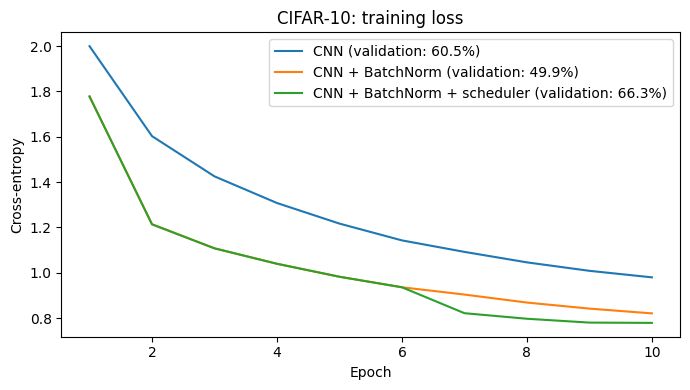

In [23]:
torch.manual_seed(SEED)
train_dataloader.generator.manual_seed(SEED)
cnn2 = CNNwithBN().to(DEVICE)
optimizer = torch.optim.SGD(cnn2.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[6, 8], gamma=0.1)

cifar_scheduled_losses = fit_scheduler(
    cnn2, train_dataloader, optimizer, epochs=CNN_EPOCHS, device=DEVICE,
    scheduler=scheduler)
_, cifar_scheduled_accuracy = predict(
    cnn2, valid_dataloader, DEVICE, verbose=False)
cifar_scheduled_accuracy = cifar_scheduled_accuracy.item()

plt.figure(figsize=(7, 4))
for label, losses, accuracy in [
    ("CNN", cifar_baseline_losses, cifar_baseline_accuracy),
    ("CNN + BatchNorm", cifar_bn_losses, cifar_bn_accuracies[-1]),
    ("CNN + BatchNorm + scheduler", cifar_scheduled_losses, cifar_scheduled_accuracy),
]:
    plt.plot(range(1, len(losses) + 1), losses,
             label=f"{label} (validation: {accuracy:.1f}%)")
plt.title("CIFAR-10: training loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy")
plt.legend()
plt.tight_layout()
plt.show()

### Residual connections

As neural networks go deeper, they are able to construct complex representations and yield superior performance. However, we cannot simply stack as many layers as we want to increase the depth.

![caption](media/resnet-no-skip-horizontal.png)

This is due to the **vanishing gradient** problem. Specifically, backpropagating the gradient to earlier layers involves repeated multiplication (with small values) rendering the gradient extremely small. This effectively means that as we go deeper, performance gets saturated. Instead of improved performance we even have degradation!

How can we reconcile this tradeoff? On the one hand, we want to increase depth but on the other hand this hurts convergence.

Enter **skip connections** [3]! The network of the previous figure now becomes the following:

![caption](media/resnet-horizontal.png)

Now, let's think why these skip connections work. First, they allow the gradient to flow via this shortcut connection, which helps mitigate the problem of vanishing gradient. Second, they allow the model to learn the identity function. In other words, this ensures that the higher layer will perform at least as good as the lower layer.

---
[3] K. He, X. Zhang, S. Ren, and J. Sun, “Deep Residual Learning for Image Recognition,” in 2016 IEEE Conference on Computer Vision and Pattern Recognition (CVPR), Las Vegas, NV, USA, Jun. 2016, pp. 770–778. doi: 10.1109/CVPR.2016.90.



First, we build the network of the first image, i.e. with no skip connections. The Resnet depicted above is characterized by an interesting pattern. It consists of "super-blocks" (see the different colors) and each one consists of two blocks that start after one residual connection and finish just before one. Notice that each color is associated with a different number, i.e. 64, 128, 256, 512.

We will build a `nn.Module` for each block and repeat it to create the super-blocks and by extension the whole architecture.

The ResNet depicted above is meant to be used for `ImageNet`, a more complex dataset compared to `CIFAR10`. For computational considerations, we amend our implementation and make a simpler version.

In [24]:
class NonResidualBlock(nn.Module):

    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels = in_planes,
            out_channels = planes,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False)

        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(
            planes,
            planes,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)

        return x


class ResNet(nn.Module):
    def __init__(self, block, num_blocks, num_classes=10):
        super().__init__()
        self.in_planes = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)
        self.linear = nn.Linear(512, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1]*(num_blocks-1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.avg_pool2d(out, 4)
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out



In [25]:
torch.manual_seed(SEED)
train_dataloader.generator.manual_seed(SEED)
model = ResNet(block=NonResidualBlock, num_blocks=[2, 2, 2, 2]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

plain_losses, _, plain_valid_accs = fit(
    model, train_dataloader, optimizer, epochs=15, device=DEVICE,
    valid_dataloader=valid_dataloader)

Epoch 0: Train Loss=1.9245, Validation Loss=1.7752, Validation acc=33.7900
Epoch 1: Train Loss=1.6036, Validation Loss=1.6463, Validation acc=38.9000
Epoch 2: Train Loss=1.3951, Validation Loss=1.3737, Validation acc=47.5000
Epoch 3: Train Loss=1.1842, Validation Loss=1.1640, Validation acc=57.9000
Epoch 4: Train Loss=1.0161, Validation Loss=1.0670, Validation acc=62.3700
Epoch 5: Train Loss=0.8879, Validation Loss=1.0261, Validation acc=63.7000
Epoch 6: Train Loss=0.8092, Validation Loss=0.9064, Validation acc=68.4900
Epoch 7: Train Loss=0.7178, Validation Loss=0.8955, Validation acc=69.8200
Epoch 8: Train Loss=0.6435, Validation Loss=0.8179, Validation acc=71.9700
Epoch 9: Train Loss=0.5861, Validation Loss=0.7255, Validation acc=74.6500
Epoch 10: Train Loss=0.5272, Validation Loss=0.9354, Validation acc=71.1700
Epoch 11: Train Loss=0.4729, Validation Loss=0.8030, Validation acc=74.3200
Epoch 12: Train Loss=0.4159, Validation Loss=0.6827, Validation acc=77.3100
Epoch 13: Train Loss=0

In [26]:
_, plain_test_accuracy = predict(model, test_dataloader, DEVICE)

Test set: Avg. loss: 0.7396, Accuracy: 7706/10000 (77%)


#### Evaluated exercise — Implementing a residual block 

Complete only `CorrectBlock.forward` using the provided layers to implement the residual block shown above.

The shortcut is already defined in `__init__`: it is the identity when `stride == 1` and `in_planes == planes`, and a $1\times1$ convolution followed by batch normalization otherwise.

Run the output-shape checks below before starting the provided training cell.

In [27]:
class CorrectBlock(nn.Module):

    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x):
        # TODO: implement the residual block forward pass
        # YOUR CODE HERE
        identity = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = F.relu(out + identity)
        return out

In [28]:
# Check both identity and projection shortcuts.
for in_channels, out_channels, stride, expected_shape in [
    (64, 64, 1, (2, 64, 32, 32)),
    (64, 128, 2, (2, 128, 16, 16)),
]:
    block = CorrectBlock(in_channels, out_channels, stride=stride)
    with torch.no_grad():
        output = block(torch.randn(2, in_channels, 32, 32))
    assert output.shape == expected_shape, (output.shape, expected_shape)
print("Output shapes match.")

Output shapes match.


Epoch 0: Train Loss=1.8127, Validation Loss=1.7976, Validation acc=39.3100
Epoch 1: Train Loss=1.3282, Validation Loss=1.7227, Validation acc=41.5900
Epoch 2: Train Loss=1.0725, Validation Loss=1.0664, Validation acc=62.1800
Epoch 3: Train Loss=0.8716, Validation Loss=0.9586, Validation acc=66.9100
Epoch 4: Train Loss=0.7089, Validation Loss=0.8216, Validation acc=70.8800
Epoch 5: Train Loss=0.5593, Validation Loss=0.8418, Validation acc=71.0700
Epoch 6: Train Loss=0.4439, Validation Loss=0.6708, Validation acc=77.5900
Epoch 7: Train Loss=0.3311, Validation Loss=0.8231, Validation acc=74.8400
Epoch 8: Train Loss=0.2341, Validation Loss=0.6747, Validation acc=78.6800
Epoch 9: Train Loss=0.1654, Validation Loss=0.7755, Validation acc=77.9700
Epoch 10: Train Loss=0.1209, Validation Loss=0.8187, Validation acc=78.9300
Epoch 11: Train Loss=0.1001, Validation Loss=0.9867, Validation acc=77.2200
Epoch 12: Train Loss=0.0830, Validation Loss=0.9252, Validation acc=77.9800
Epoch 13: Train Loss=0

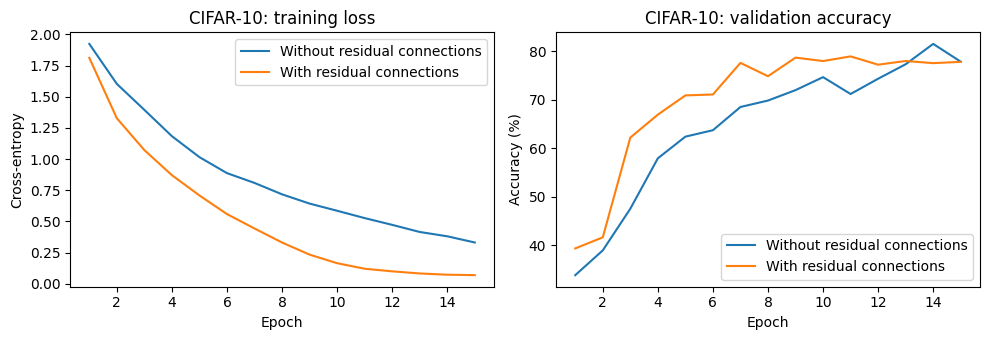

In [29]:
torch.manual_seed(SEED)
train_dataloader.generator.manual_seed(SEED)
model = ResNet(block=CorrectBlock, num_blocks=[2, 2, 2, 2]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

residual_losses, _, residual_valid_accs = fit(
    model, train_dataloader, optimizer, epochs=15, device=DEVICE,
    valid_dataloader=valid_dataloader)
_, residual_test_accuracy = predict(model, test_dataloader, DEVICE)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, losses, accuracies in [
    ("Without residual connections", plain_losses, plain_valid_accs),
    ("With residual connections", residual_losses, residual_valid_accs),
]:
    epochs = range(1, len(losses) + 1)
    axes[0].plot(epochs, losses, label=label)
    axes[1].plot(epochs, accuracies, label=label)
axes[0].set(title="CIFAR-10: training loss", ylabel="Cross-entropy")
axes[1].set(title="CIFAR-10: validation accuracy", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

**Discussion:** Compare the learning curves and final accuracies of the models with and without residual connections. How might a learning-rate scheduler affect the results?

The model with residual connections learns faster and has a lower training loss. Both models reach a similar final validation accuracy of around 78%, but the model without residual connections reaches a higher peak accuracy of about 82%.

A learning-rate scheduler could improve the results by gradually reducing the learning rate over time. This could help the models converge more smoothly and achieve better final accuracy.